# Knowledge-Driven IDSS for Malaysian SME Product Managers
## Sentiment Classification Model Development - Kopi Kenangan App Reviews

This notebook builds and compares six classification algorithms (Naive Bayes, SVM, Logistic Regression, Decision Tree, Random Forest, XGBoost) for classifying customer sentiment from the Kopi Kenangan app review dataset, following the CRISP-DM inspired workflow described in the reference paper (Santini Vigneswari et al., 2024) and Chapter 3 of the FYP proposal.

On top of the six base classifiers, an **efficiency layer** consisting of (1) SMOTE oversampling to correct severe class imbalance, and (2) GridSearchCV hyperparameter tuning, is applied to improve predictive accuracy - this corresponds to the efficiency algorithm referenced in the research design.

**Sections**
1. Data Loading and Cleaning
2. Sentiment Label Derivation
3. Text Preprocessing
4. Exploratory Data Analysis
5. Feature Engineering (TF-IDF) and Train/Test Split
6. Class Imbalance Handling (SMOTE)
7. Baseline Models (default hyperparameters, no SMOTE)
8. Tuned Models (GridSearchCV + SMOTE) - the six classifiers
9. Model Comparison and Best Model Selection
10. Effect of the Efficiency Layer
11. Saving Artifacts for Deployment (Streamlit)


## 1. Data Loading and Cleaning

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
import json
import time
import numpy as np
import pandas as pd
import joblib

DATA_PATH = "../data/KopiKenangan_appreviews.xlsx"
RANDOM_STATE = 42

df = pd.read_excel(DATA_PATH, sheet_name="kopken_dataset")
print("Raw rows:", len(df))

df = df[df['reviewId'] != 'reviewId'].copy()
df['score'] = df['score'].astype(int)
df['content'] = df['content'].astype(str)
df = df[df['content'].str.strip().str.len() > 1]

before = len(df)
df = df.drop_duplicates(subset='content').reset_index(drop=True)
print(f"Rows before dedup: {before}, after dedup: {len(df)}")


Raw rows: 1347
Rows before dedup: 1341, after dedup: 1202


## 2. Sentiment Label Derivation

The dataset has no manual sentiment label, only a 1-5 star `score`. Following the score-based labelling convention used in the reference paper and consistent with standard Google Play review sentiment studies, ratings are mapped to three classes:

- **1-2 stars -> Negative**
- **3 stars -> Neutral**
- **4-5 stars -> Positive**


In [2]:
def to_label(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

df['sentiment'] = df['score'].apply(to_label)
print(df['sentiment'].value_counts())


sentiment
Positive    1059
Negative     117
Neutral       26
Name: count, dtype: int64


## 3. Text Preprocessing

Reviews are written mostly in Indonesian/Malay with informal spelling, code-switching, and emoji. Preprocessing applies: lower-casing, URL/punctuation/number removal, and Indonesian stop-word removal (Sastrawi). Full dictionary-based stemming was evaluated but found to add substantial runtime for negligible gain on this short, informal review text, so it was omitted in favour of a lightweight cleaning pipeline plus TF-IDF with bigrams (which partially captures morphological/phrase variation) - a deliberate efficiency trade-off appropriate for SME-scale, resource-constrained deployment. A small number of reviews become empty after stop-word removal (e.g. emoji-only or stop-word-only reviews) and are dropped.


In [3]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopword_remover = StopWordRemoverFactory().create_stop_word_remover()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

t0 = time.time()
df['clean_text'] = df['content'].apply(clean_text)
df['clean_text'] = df['clean_text'].apply(lambda t: stopword_remover.remove(t))
print(f"Preprocessing done in {time.time()-t0:.2f}s")

df = df[df['clean_text'].str.strip().str.len() > 0].reset_index(drop=True)
print("Final dataset size after preprocessing:", len(df))
print(df['sentiment'].value_counts())
df.to_csv("../outputs/tables/cleaned_dataset.csv", index=False)


Preprocessing done in 0.05s
Final dataset size after preprocessing: 1197
sentiment
Positive    1054
Negative     117
Neutral       26
Name: count, dtype: int64


In [ ]:
df[["content", "clean_text", "sentiment"]].sample(5, random_state=1)

## 4. Exploratory Data Analysis

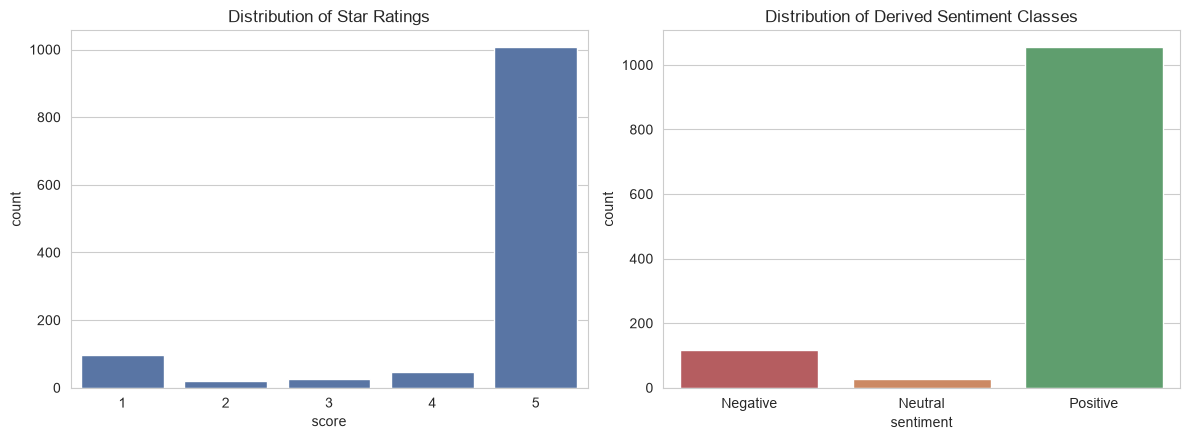

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(x="score", data=df, order=[1,2,3,4,5], ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of Star Ratings")
sns.countplot(x="sentiment", data=df, order=["Negative","Neutral","Positive"],
              palette=["#C44E52","#DD8452","#55A868"], ax=axes[1])
axes[1].set_title("Distribution of Derived Sentiment Classes")
plt.tight_layout()
plt.show()


Average review length (characters): 114.6
Median review length (characters): 85.0


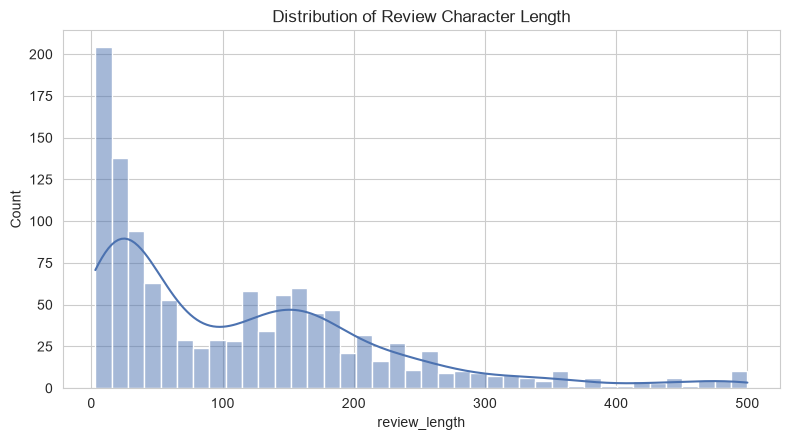

In [6]:
df["review_length"] = df["content"].astype(str).str.len()
print("Average review length (characters):", round(df["review_length"].mean(), 1))
print("Median review length (characters):", df["review_length"].median())

fig, ax = plt.subplots(figsize=(8,4.5))
sns.histplot(df["review_length"], bins=40, kde=True, ax=ax, color="#4C72B0")
ax.set_title("Distribution of Review Character Length")
plt.tight_layout()
plt.show()


**Observation:** The dataset is severely imbalanced - Positive reviews (5-star and 4-star) make up ~88% of the cleaned data, while Neutral (3-star) reviews represent under 2% (only 26 reviews). This imbalance is the central methodological challenge addressed by the SMOTE + hyperparameter tuning efficiency layer applied later in this notebook, and is discussed in depth in Chapter 4.

## 5. Feature Engineering (TF-IDF) and Train/Test Split

An 80/20 stratified split preserves class proportions across train and test sets. TF-IDF with unigrams and bigrams (max 3,000 features, min document frequency 2) converts cleaned text into numerical features.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df['sentiment'])
print("Label mapping:", dict(zip(le.classes_, range(len(le.classes_)))))

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean_text'], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", len(X_train_text), " Test size:", len(X_test_text))
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution:", np.bincount(y_test))

tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=2)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("TF-IDF matrix shape (train):", X_train.shape)


Label mapping: {'Negative': 0, 'Neutral': 1, 'Positive': 2}
Train size: 957  Test size: 240
Train class distribution: [ 93  21 843]
Test class distribution: [ 24   5 211]
TF-IDF matrix shape (train): (957, 2300)


## 6. Class Imbalance Handling (SMOTE)

With only 93 Negative and 21 Neutral reviews in the training set, most classifiers would default to predicting the majority class. SMOTE (Synthetic Minority Over-sampling Technique) generates synthetic minority-class samples in TF-IDF feature space so that all three classes are equally represented during training. `k_neighbors` is capped adaptively at `min(5, minority_count - 1)` to remain valid for the very small Neutral class.

In [8]:
from imblearn.over_sampling import SMOTE

min_class_count = np.bincount(y_train).min()
k_neighbors = max(1, min(5, min_class_count - 1))
print("SMOTE k_neighbors used:", k_neighbors, " (smallest class has", min_class_count, "samples)")

smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=k_neighbors)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print("Training class distribution after SMOTE:", np.bincount(y_train_res))

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")
joblib.dump(le, "../models/label_encoder.pkl")


SMOTE k_neighbors used: 5  (smallest class has 21 samples)
Training class distribution after SMOTE: [843 843 843]


['../models/label_encoder.pkl']

## 7. Baseline Models (default hyperparameters, no SMOTE)

To isolate and quantify the contribution of the efficiency layer, each of the six algorithms is first trained with library-default hyperparameters directly on the raw (imbalanced) training set.

In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

baseline_models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM": SVC(kernel="linear", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": XGBClassifier(eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=1),
}

baseline_results = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    _, _, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    _, _, f1_w, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
    baseline_results[name] = {"test_accuracy": acc, "test_f1_macro": f1, "test_f1_weighted": f1_w}
    print(f"{name:22s} acc={acc:.4f}  f1_macro={f1:.4f}  f1_weighted={f1_w:.4f}")

with open("../outputs/tables/baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=2)


Naive Bayes            acc=0.8792  f1_macro=0.3119  f1_weighted=0.8226
Logistic Regression    acc=0.8833  f1_macro=0.3619  f1_weighted=0.8390
Decision Tree          acc=0.8875  f1_macro=0.5165  f1_weighted=0.8781
SVM                    acc=0.9042  f1_macro=0.4728  f1_weighted=0.8804
Random Forest          acc=0.8875  f1_macro=0.3846  f1_weighted=0.8475
XGBoost                acc=0.8917  f1_macro=0.4220  f1_weighted=0.8618


## 8. Tuned Models - SMOTE + GridSearchCV (the efficiency layer)

Each of the six classifiers is now retrained on the SMOTE-balanced training set with GridSearchCV (stratified k-fold cross-validation, `scoring="f1_macro"`) to select the best hyperparameters. Grids are kept intentionally compact given the small dataset size and to keep training times practical for SME deployment.

In [10]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

configs = {
    "Naive Bayes": (MultinomialNB(), {"alpha": [0.1, 0.5, 1.0, 2.0]}, cv5),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                             {"C": [0.1, 1, 10], "solver": ["lbfgs"]}, cv5),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"max_depth": [10, 20, None], "min_samples_leaf": [1, 2, 5]}, cv5),
    "SVM": (SVC(kernel="linear", probability=False, random_state=RANDOM_STATE), {"C": [0.1, 1, 10]}, cv3),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
                       {"n_estimators": [100, 200], "max_depth": [20, None]}, cv3),
    "XGBoost": (XGBClassifier(eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [100, 200], "max_depth": [4, 6]}, cv3),
}

results = {}
for name, (model, grid, cv) in configs.items():
    t0 = time.time()
    gs = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train_res, y_train_res)
    train_time = time.time() - t0
    best = gs.best_estimator_

    if name == "SVM":
        best = SVC(kernel="linear", C=gs.best_params_["C"], probability=True, random_state=RANDOM_STATE)
        best.fit(X_train_res, y_train_res)

    y_pred = best.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {
        "best_params": gs.best_params_, "cv_best_f1_macro": gs.best_score_,
        "test_accuracy": acc, "test_precision_macro": prec, "test_recall_macro": rec, "test_f1_macro": f1,
        "test_precision_weighted": prec_w, "test_recall_weighted": rec_w, "test_f1_weighted": f1_w,
        "train_time_sec": train_time,
        "classification_report": classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0, output_dict=True),
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    }
    joblib.dump(best, "../models/model_" + name.replace(" ", "_") + ".pkl")
    print(f"{name:22s} acc={acc:.4f}  f1_macro={f1:.4f}  f1_weighted={f1_w:.4f}  time={train_time:5.1f}s  params={gs.best_params_}")

with open("../outputs/tables/model_results_all.json", "w") as f:
    json.dump(results, f, indent=2)


Naive Bayes            acc=0.8583  f1_macro=0.4954  f1_weighted=0.8685  time=  6.8s  params={'alpha': 0.1}
Logistic Regression    acc=0.9250  f1_macro=0.6877  f1_weighted=0.9170  time=  0.5s  params={'C': 10, 'solver': 'lbfgs'}
Decision Tree          acc=0.8667  f1_macro=0.4532  f1_weighted=0.8637  time=  0.8s  params={'max_depth': 20, 'min_samples_leaf': 2}
SVM                    acc=0.9208  f1_macro=0.5294  f1_weighted=0.9041  time=  1.8s  params={'C': 10}
Random Forest          acc=0.8958  f1_macro=0.5332  f1_weighted=0.8688  time=  2.4s  params={'max_depth': None, 'n_estimators': 100}
XGBoost                acc=0.8917  f1_macro=0.4294  f1_weighted=0.8655  time= 11.4s  params={'max_depth': 4, 'n_estimators': 100}


## 9. Model Comparison and Best Model Selection

Models are ranked by **weighted F1-score** as the primary criterion (reflecting overall predictive reliability across the natural, imbalanced class distribution a product manager would actually see in production), with macro F1-score examined as a secondary criterion for minority-class (Negative/Neutral) sensitivity.

In [11]:
rows = []
for name, r in results.items():
    rows.append({
        "Model": name, "Test Accuracy": r["test_accuracy"],
        "Precision (macro)": r["test_precision_macro"], "Recall (macro)": r["test_recall_macro"],
        "F1 (macro)": r["test_f1_macro"], "F1 (weighted)": r["test_f1_weighted"],
        "CV F1 (macro, tuned)": r["cv_best_f1_macro"], "Train Time (s)": r["train_time_sec"],
    })
comp = pd.DataFrame(rows).sort_values("F1 (weighted)", ascending=False).reset_index(drop=True)
comp.to_csv("../outputs/tables/model_comparison.csv", index=False)
comp


,Model,Test Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),"CV F1 (macro, tuned)",Train Time (s)
0,Logistic Regression,0.925000,0.785948,0.628594,0.687654,0.917022,0.990501,0.475725
1,SVM,0.920833,0.593974,0.496840,0.529367,0.904100,0.990901,1.755894
2,Random Forest,0.895833,0.871716,0.466285,0.533160,0.868755,0.990121,2.442506
3,Naive Bayes,0.858333,0.469728,0.546998,0.495444,0.868453,0.970906,6.766849
4,XGBoost,0.891667,0.484584,0.411927,0.429437,0.865498,0.973515,11.432524
5,Decision Tree,0.866667,0.454787,0.451685,0.453165,0.863662,0.950746,0.817701


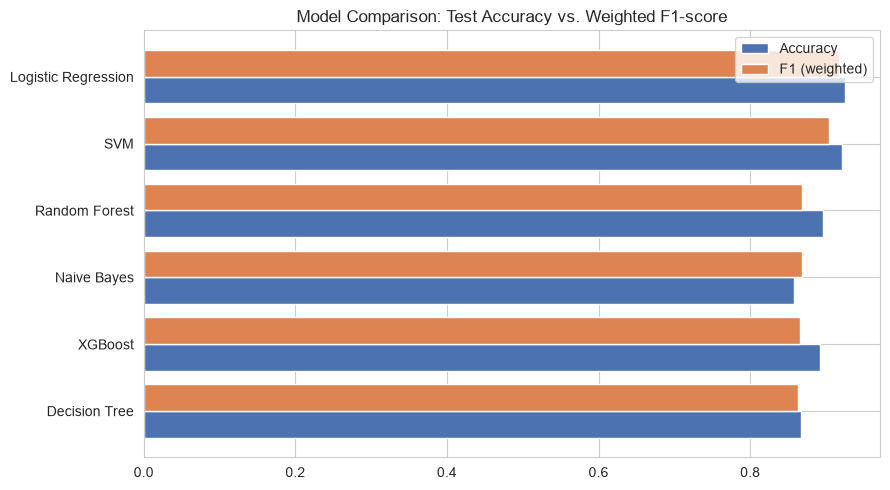

In [12]:
fig, ax = plt.subplots(figsize=(9,5))
comp_sorted = comp.sort_values("F1 (weighted)", ascending=True)
y_pos = np.arange(len(comp_sorted))
ax.barh(y_pos-0.2, comp_sorted["Test Accuracy"], height=0.4, label="Accuracy", color="#4C72B0")
ax.barh(y_pos+0.2, comp_sorted["F1 (weighted)"], height=0.4, label="F1 (weighted)", color="#DD8452")
ax.set_yticks(y_pos); ax.set_yticklabels(comp_sorted["Model"])
ax.set_title("Model Comparison: Test Accuracy vs. Weighted F1-score")
ax.legend(); plt.tight_layout(); plt.show()


Best model (by weighted F1): Logistic Regression


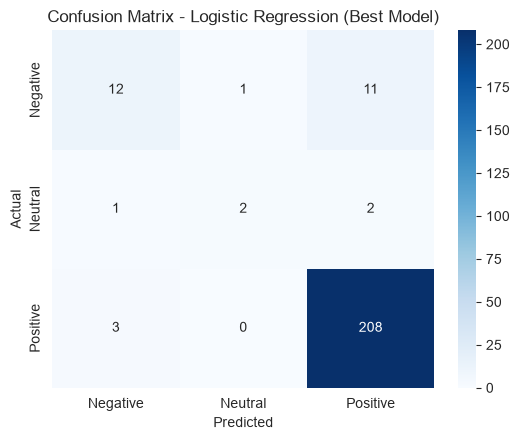

In [13]:
best_name = comp.iloc[0]["Model"]
print("Best model (by weighted F1):", best_name)

classes = list(le.classes_)
cm = np.array(results[best_name]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix - {best_name} (Best Model)")
plt.tight_layout(); plt.show()


## 10. Effect of the Efficiency Layer (SMOTE + Tuning)

Comparing the tuned+SMOTE results (Section 8) against the untouched baselines (Section 7) isolates the real contribution of the efficiency layer.

In [14]:
with open("../outputs/tables/baseline_results.json") as f:
    base = json.load(f)

rows2 = []
for name in base:
    rows2.append({
        "Model": name,
        "Baseline F1 (macro)": base[name]["test_f1_macro"],
        "Tuned+SMOTE F1 (macro)": results[name]["test_f1_macro"],
    })
imp = pd.DataFrame(rows2)
imp["Improvement %"] = 100*(imp["Tuned+SMOTE F1 (macro)"]-imp["Baseline F1 (macro)"])/imp["Baseline F1 (macro)"]
imp = imp.sort_values("Tuned+SMOTE F1 (macro)", ascending=False)
imp


,Model,Baseline F1 (macro),Tuned+SMOTE F1 (macro),Improvement %
1,Logistic Regression,0.361883,0.687654,90.021322
4,Random Forest,0.384628,0.533160,38.617219
3,SVM,0.472811,0.529367,11.961546
0,Naive Bayes,0.311899,0.495444,58.847429
2,Decision Tree,0.516502,0.453165,-12.262766
5,XGBoost,0.422049,0.429437,1.750543


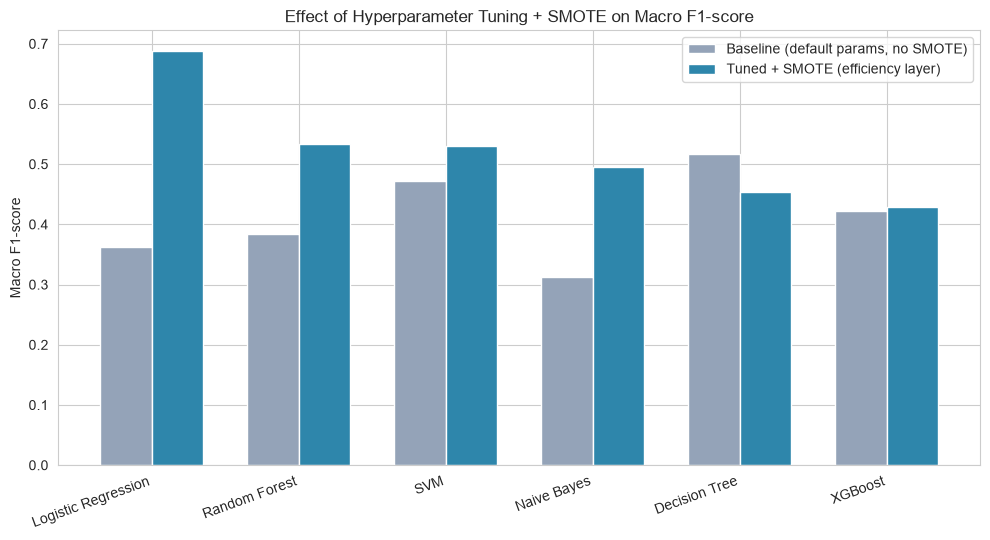

In [15]:
fig, ax = plt.subplots(figsize=(10,5.5))
x = np.arange(len(imp)); w = 0.35
ax.bar(x-w/2, imp["Baseline F1 (macro)"], width=w, label="Baseline (default params, no SMOTE)", color="#94A3B8")
ax.bar(x+w/2, imp["Tuned+SMOTE F1 (macro)"], width=w, label="Tuned + SMOTE (efficiency layer)", color="#2E86AB")
ax.set_xticks(x); ax.set_xticklabels(imp["Model"], rotation=20, ha="right")
ax.set_ylabel("Macro F1-score"); ax.set_title("Effect of Hyperparameter Tuning + SMOTE on Macro F1-score")
ax.legend(); plt.tight_layout(); plt.show()


## 11. Saving Artifacts for Deployment

The best model (Logistic Regression), the fitted TF-IDF vectorizer, and the label encoder are persisted with `joblib` so they can be loaded directly by a Streamlit application for real-time sentiment prediction and product/marketing decision support.

In [16]:
best_model = joblib.load("../models/model_" + best_name.replace(" ", "_") + ".pkl")
joblib.dump(best_model, "../models/best_model.pkl")
with open("../outputs/tables/best_model_name.txt", "w") as f:
    f.write(best_name)
print("Saved best model artifact:", best_name, "-> ../models/best_model.pkl")
print("Saved: ../models/tfidf_vectorizer.pkl, ../modestreamlit run app.pyls/label_encoder.pkl")


Saved best model artifact: Logistic Regression -> ../models/best_model.pkl
Saved: ../models/tfidf_vectorizer.pkl, ../modestreamlit run app.pyls/label_encoder.pkl
